# Mini Project 1 · Group A
## Detection and Analysis of Performance Loss in a PLC-Controlled Production System Using Unsupervised Learning
### Stage 3: Feature Audit, Constant/Duplicate Signal Exclusion, and Encoding

**Lead Author:** Lakshmi Narayana Reddy Mandi  
**Team Members:** Neeraj Bhuma, Lakshmi Narayana Reddy Mandi, Naga Sai Priyanka Truvidhula  
**Supervisor:** Prof. Felix Georg Müller  
**Institution:** Hochschule Albstadt-Sigmaringen (November 2026)

In [1]:
import pandas as pd  # tables
from pathlib import Path
import os

# Dynamically locate project root, raw data and output directories
def get_project_dirs():
    current = Path.cwd().resolve()
    root = next((p for p in [current] + list(current.parents) if (p / "02_Data_and_Outputs").exists() or (p / "01_Notebooks").exists()), current)
    out_candidates = [
        root / "02_Data_and_Outputs" / "Generated_Outputs",
        root / "Generated_Outputs",
        current / "Generated_Outputs",
        current.parent / "02_Data_and_Outputs" / "Generated_Outputs",
        root / "02_Data_and_Outputs" / "Raw_Data",
        current,
    ]
    out_dir = next((p for p in out_candidates if (p / "merged_85ms.csv").exists()), root / "02_Data_and_Outputs" / "Generated_Outputs")
    out_dir.mkdir(parents=True, exist_ok=True)
    raw_candidates = [
        root / "02_Data_and_Outputs" / "Raw_Data",
        root / "Raw_Data",
        current / "Raw_Data",
        current.parent / "02_Data_and_Outputs" / "Raw_Data",
    ]
    raw_dir = next((p for p in raw_candidates if p.exists() and list(p.glob("Variablen*.xlsx"))), root / "02_Data_and_Outputs" / "Raw_Data")
    return root, raw_dir, out_dir

PROJECT_ROOT, RAW_DIR, OUT_DIR = get_project_dirs()
merged_path = OUT_DIR / "merged_85ms.csv"
if not merged_path.exists():
    found = list(PROJECT_ROOT.glob("**/merged_85ms.csv"))
    if found:
        merged_path = found[0]

print(f"Loading merged data from: {merged_path}")
data = pd.read_csv(merged_path)  # read the table from the CSV

HELPERS = ['utc_time', 'timestamp_beckhoff', 'beck_time', 'beck_age_ms',
           'timestamp_siemens', 'sie_time', 'sie_age_ms', 't_s',
           'unix_ms', 'ms', 'BECK_src_ms', 'SIE_src_ms',
           'BECK_age_ms', 'SIE_age_ms']  # timing and merge columns
helpers = [c for c in HELPERS if c in data.columns]  # those present
signals = [c for c in data.columns if c not in helpers]  # process signals

print(f'Rows: {len(data)}, columns: {len(data.columns)}')  # 5945, 202
print(f'Timing/merge helpers ({len(helpers)}): ' + ', '.join(helpers))
print(f'Candidate signal columns: {len(signals)}')  # expect 195

nonnum = [c for c in signals  # signals that are not numeric
          if not pd.api.types.is_numeric_dtype(data[c])]
print(f'\nNon-numeric signals to inspect: {len(nonnum)}')  # expect 0
for c in nonnum[:10]:  # show up to 10 of them
    examples = list(data[c].dropna().unique()[:3])  # 3 example values
    print(f'  {c} ({data[c].dtype}), examples: {examples}')
if len(nonnum) > 10:  # say how many were not shown
    print(f'  ... and {len(nonnum) - 10} more')

miss = data[signals].isna().sum()  # missing values per signal
miss = miss[miss > 0].sort_values(ascending=False)  # only those with some
print(f'\nSignal columns with missing values: {len(miss)}')  # expect 0
if len(miss):  # only if there is something to show
    print(miss.head(10).to_string())  # the 10 worst columns
    if len(miss) > 10:  # say how many were not shown
        print(f'  ... and {len(miss) - 10} more')

all_missing = [c for c in signals if data[c].notna().sum() == 0]  # empty
const = [c for c in signals  # exactly one observed value
         if data[c].nunique(dropna=True) == 1]
print(f'\nAll-missing signals: {len(all_missing)}')  # expect 0
print(', '.join(all_missing) if all_missing else 'None')
print(f'\nSingle observed value (ignoring missing): {len(const)}')  # 40
print(', '.join(const) if const else 'None')

# Equality requires matching values, missing positions and dtype.
buckets = {}  # signals grouped by (dtype, non-missing, distinct values)
for c in signals:  # sort every signal into a bucket
    key = (str(data[c].dtype), int(data[c].notna().sum()),
           int(data[c].nunique(dropna=True)))  # cheap pre-check
    buckets.setdefault(key, []).append(c)  # add to its bucket

dup_groups = []  # groups of identical columns
for bucket in buckets.values():  # compare only inside a bucket
    remaining = list(bucket)  # columns not yet assigned to a group
    while remaining:  # until every column is checked
        reference = remaining.pop(0)  # take the first as reference
        same = [c for c in remaining  # columns identical to the reference
                if data[c].equals(data[reference])]
        if same:  # at least one identical column
            dup_groups.append([reference] + same)  # store the group
            remaining = [c for c in remaining if c not in same]  # rest

print(f'\nIdentical recorded-column groups: {len(dup_groups)}')  # 11
for group in dup_groups:  # print every group
    print('  ' + ', '.join(group))

print('\nNo rows or columns removed; no values changed.')


Loading merged data from: /Users/lakshminarayanareddymandu/Downloads/B4 Project/02_Data_and_Outputs/Generated_Outputs/merged_85ms.csv
Rows: 5945, columns: 202
Timing/merge helpers (7): utc_time, timestamp_beckhoff, beck_time, beck_age_ms, timestamp_siemens, sie_time, sie_age_ms
Candidate signal columns: 195

Non-numeric signals to inspect: 0

Signal columns with missing values: 0

All-missing signals: 0
None

Single observed value (ignoring missing): 40
VG.I3_ref_switch_rotate, WH.I4_Ref_swtich_vertical, WH.A1_trail_sensor_lower, WH.A2_trail_sensor_upper, VG.safeCurtainLong, Pallets.Conveyor_belt_lift, VG.atHome, VG.error_robot, M34.4, M38.0, M38.1, C0, EW288, C1, C2, M2.0, M2.1, M2.2, M2.3, M3.0, M3.1, C4, M4.0, M5.7, M7.0, A6.4, A6.5, M24.0, M24.1, A201.1, M24.2, EW258, EW256, M24.5, M0.0, E6.0, E6.1, E200.1, E1.7, E200.2

Identical recorded-column groups: 11
  A0.2, A200.4
  A0.3, A200.5
  A0.4, A200.6
  M3.4, M4.5
  M6.0, M7.4
  M24.3, M0.3
  M0.5, M1.3
  VG.I3_ref_switch_rotate, W

**What:**
- Load the cleaned merged table merged_85.csv and separate the process signals from the timing and merge helper columns
- Audit the 195 candidate signals: data type, missing values, signals with only one observed value, and signals whose recorded values are identical to another signal

**Why:**
- We need to know exactly what is in the table before we decide which signals go into a distance-based model
- The audit only reads. No row or column is removed and no value is changed
- Two columns are identical only if values, missing positions and data type all match. We compare the full columns with .equals(), and group them first by type, number of values and number of distinct values to keep the comparison short

**Output:**
- Rows: 5945, columns: 202
- 7 timing and merge helpers, 195 candidate signal columns
- Non-numeric signals: 0, signals with missing values: 0, all-missing signals: 0
- 40 signals with a single observed value
- 11 groups of identical recorded columns: 7 pairs of signals that vary (the three pusher outputs A0.2/A0.3/A0.4 with A200.4/A200.5/A200.6, plus M3.4/M4.5, M6.0/M7.4, M24.3/M0.3, M0.5/M1.3) and 4 groups of constant signals

**Next:** read the meaning of these signals in the signal dictionary

In [2]:
from pathlib import Path  # file paths
import openpyxl  # reads the Excel dictionary

# Dynamically locate dictionary folder
folder = RAW_DIR if ("RAW_DIR" in globals() and list(RAW_DIR.glob("Variablen*.xlsx"))) else Path("Raw_Data")
files = sorted(folder.glob('Variablen*.xlsx'))  # find it by pattern
if len(files) != 1:  # fallback search across project
    files = sorted(PROJECT_ROOT.glob('**/Variablen*.xlsx'))
if len(files) != 1:  # stop if the file is not unique
    raise ValueError(f'Expected one dictionary file, found: {files}')

workbook = openpyxl.load_workbook(files[0], read_only=True)  # open it
book = {}  # signal name -> list of (sheet, row)
for sheet in workbook.sheetnames:  # Siemens and Beckhoff
    records = [  # all non-empty rows of the sheet
        row for row in workbook[sheet].iter_rows(values_only=True)
        if row and row[0] is not None
    ]
    if not records:  # skip an empty sheet
        continue
    print(f'\nSheet: {sheet}; first row: {records[0]}')  # header row
    for row in records[1:]:  # skip the header
        name = str(row[0]).strip()  # signal name without spaces
        book.setdefault(name, []).append((sheet, row))  # keep the sheet
workbook.close()  # close the file


def show_meaning(name):  # print the dictionary entry of one signal
    entries = book.get(name.strip(), [])  # all entries of this name
    if not entries:  # not in the dictionary
        print(f'  {name}: NOT FOUND')
        return
    for sheet, row in entries:  # usually one entry
        fields = '; '.join(  # all non-empty fields of the row
            f'field {i}: {value}'
            for i, value in enumerate(row)
            if value is not None and str(value).strip()
        )
        print(f'  {name} [{sheet}]: {fields}')


varying_groups = [  # identical groups whose values do change
    group for group in dup_groups
    if data[group[0]].nunique(dropna=True) > 1
]
print('\nIDENTICAL VARYING RECORDINGS:')
for group in varying_groups:  # every such group
    print('\nGroup: ' + ', '.join(group))
    for name in group:  # meaning of each member
        show_meaning(name)

print('\nCONSTANT SIGNALS:')
for name in const:  # meaning of each constant signal
    show_meaning(name)

print('\nRead-only check. Nothing removed or changed.')



Sheet: Siemens; first row: ('Variablenname', 'Datentyp', 'Kommentar', 'Station', 'Symbol')

Sheet: Beckhoff; first row: ('Variablenname / Beschreibung', 'Station')

IDENTICAL VARYING RECORDINGS:

Group: A0.2, A200.4
  A0.2 [Siemens]: field 0: A0.2; field 1: Bool; field 2: White Block, Pneumatic pusher activated (output); field 3: Sorting station; field 4: pneu_pusher_white
  A200.4 [Siemens]: field 0: A200.4; field 1: Bool; field 2: White Block sorting, amount data to Beckhoff; field 3: Beckhoff; field 4: White_pneu_data

Group: A0.3, A200.5
  A0.3 [Siemens]: field 0: A0.3; field 1: Bool; field 2: Red Block, Pneumatic pusher activated (output); field 3: Sorting station; field 4: pneu_pusher_red
  A200.5 [Siemens]: field 0: A200.5; field 1: Bool; field 2: Red Block sorting, amount data to Beckhoff; field 3: Beckhoff; field 4: red_pneu_data

Group: A0.4, A200.6
  A0.4 [Siemens]: field 0: A0.4; field 1: Bool; field 2: Blue block, Pneumatic pusher activated (output); field 3: Sorting stat

**What:**
- Open the signal dictionary (Variablen*.xlsx) and read both sheets (Siemens and Beckhoff) into one lookup, book
- Print the dictionary entry (data type, comment, station, symbol) for the identical varying signal groups and for the 40 constant signals
- Define show_meaning(name) to print the entry of one signal

**Why:**
- We name signals and stations only through the dictionary, not from the signal names
- The Siemens sheet has five fields per signal (Variablenname, Datentyp, Kommentar, Station, Symbol), the Beckhoff sheet only two (Variablenname / Beschreibung, Station), so we keep each row with its sheet name and print the fields as they are
- The cell stops with an error if not exactly one dictionary file is found
- Read-only: nothing is removed or changed

**Output:**
- Header rows of both sheets
- For the three pusher pairs: A0.2, A0.3, A0.4 are the pneumatic pusher outputs for the white, red and blue block (Sorting station), A200.4, A200.5, A200.6 are the same events sent as data to the Beckhoff (station Beckhoff)
- For the other four pairs: different control meanings, for example M3.4 "drives oven in" and M4.5 "activates vacuum to oven SR" (Drilling station)
- The dictionary entry of each of the 40 constant signals (list in the output)

**Next:** decide which signals to exclude from the model matrix (next markdown cell and cell 4)

### Feature-selection decision

One sample is one timestamped row of the merged recording. The audit found 5,945 rows and 195 numerical signal columns, with no missing values.

**1. We exclude the 40 constant signals from the model matrix only.**
- Evidence: each has exactly one observed value in this recording. In a Euclidean distance between two rows its contribution is zero, (c - c)^2 = 0, so excluding it does not change those distances.
- This does not mean the signal is unimportant, inactive or constant in other recordings.

**2. We exclude A200.4, A200.5 and A200.6 and keep A0.2, A0.3 and A0.4.**
- Evidence: each pair has identical recorded values. The dictionary describes A0.2 to A0.4 as pusher-activation outputs and A200.4 to A200.6 as sorting data sent to the Beckhoff. We keep the direct actuator signal.
- Keeping both copies would double that pattern's weight in the squared Euclidean distance.
- This is a decision for this recording. It does not prove that both channels always behave the same.

**3. We keep the other four matching pairs for now.**
- Evidence: their dictionary descriptions show different control meanings, and equality in one recording does not show that one of them is not needed.
- Keeping both gives their shared pattern extra weight, so this is a documented starting choice and not a proven best selection.

**Result:** 195 - 40 - 3 = 152 features. The source CSV and all rows stay unchanged. Model choice and scaling are still open. Agreement with the stop rules is not fully independent evidence, because the raw curtain and screen channels are still among the features.

In [3]:
import pandas as pd  # tables

# Re-read from dynamically resolved merged_path
data = pd.read_csv(merged_path)  # read the table from the CSV

HELPERS = ['utc_time', 'timestamp_beckhoff', 'beck_time', 'beck_age_ms',
           'timestamp_siemens', 'sie_time', 'sie_age_ms', 't_s',
           'unix_ms', 'ms', 'BECK_src_ms', 'SIE_src_ms',
           'BECK_age_ms', 'SIE_age_ms']  # timing and merge columns
signals = [c for c in data.columns if c not in HELPERS]  # process signals

CONSTANT_40 = [  # signals with one observed value (cell 1)
    'VG.I3_ref_switch_rotate', 'WH.I4_Ref_swtich_vertical',
    'WH.A1_trail_sensor_lower', 'WH.A2_trail_sensor_upper',
    'VG.safeCurtainLong', 'Pallets.Conveyor_belt_lift',
    'VG.atHome', 'VG.error_robot', 'M34.4', 'M38.0', 'M38.1',
    'C0', 'EW288', 'C1', 'C2', 'M2.0', 'M2.1', 'M2.2', 'M2.3',
    'M3.0', 'M3.1', 'C4', 'M4.0', 'M5.7', 'M7.0', 'A6.4',
    'A6.5', 'M24.0', 'M24.1', 'A201.1', 'M24.2', 'EW258',
    'EW256', 'M24.5', 'M0.0', 'E6.0', 'E6.1', 'E200.1',
    'E1.7', 'E200.2',
]
COMM_COPIES = {'A200.4': 'A0.2', 'A200.5': 'A0.3', 'A200.6': 'A0.4'}  # copy

bad_const = [  # listed constants that are missing or not constant
    c for c in CONSTANT_40
    if c not in data.columns or data[c].nunique(dropna=True) != 1
]
bad_pairs = [  # listed copies that are missing or not identical
    f'{copy} vs {original}'
    for copy, original in COMM_COPIES.items()
    if copy not in data.columns or original not in data.columns
    or not data[copy].equals(data[original])
]
if bad_const or bad_pairs:  # stop if the audit no longer holds
    raise ValueError(
        'Audit conditions changed. Review before excluding: '
        f'{bad_const} {bad_pairs}'
    )
if data[signals].isna().any().any():  # stop if a signal has gaps
    raise ValueError('Missing signal values found; review before proceeding.')

reason_rows = [  # reason for each constant signal
    (c, 'One observed value throughout this recording')
    for c in CONSTANT_40
]
reason_rows += [  # reason for each duplicate communication column
    (copy, f'Identical to {original}; sorting data sent to Beckhoff')
    for copy, original in COMM_COPIES.items()
]
exclusions = pd.DataFrame(reason_rows, columns=['column', 'reason'])  # 43
excluded_names = set(exclusions['column'])  # names for a fast lookup
features = [c for c in signals if c not in excluded_names]  # kept signals
X = data[features].copy()  # feature matrix, a copy of the source columns

assert len(features) == 152, f'Expected 152 features, got {len(features)}'
assert X.index.equals(data.index), 'Row alignment changed'  # same rows

print(f'Source data: {data.shape} (unchanged)')  # (5945, 202)
print(f'Candidate signals: {len(signals)}')  # 195
print(f'Excluded from model matrix: {len(exclusions)}')  # 43
print(f'Feature matrix X: {X.shape}')  # (5945, 152)
print('\nExclusions and reasons:')
print(exclusions.to_string(index=False))  # all 43 with their reason
print('\nNo source rows or columns deleted. No scaling or training.')


Source data: (5945, 202) (unchanged)
Candidate signals: 195
Excluded from model matrix: 43
Feature matrix X: (5945, 152)

Exclusions and reasons:
                    column                                           reason
   VG.I3_ref_switch_rotate     One observed value throughout this recording
 WH.I4_Ref_swtich_vertical     One observed value throughout this recording
  WH.A1_trail_sensor_lower     One observed value throughout this recording
  WH.A2_trail_sensor_upper     One observed value throughout this recording
        VG.safeCurtainLong     One observed value throughout this recording
Pallets.Conveyor_belt_lift     One observed value throughout this recording
                 VG.atHome     One observed value throughout this recording
            VG.error_robot     One observed value throughout this recording
                     M34.4     One observed value throughout this recording
                     M38.0     One observed value throughout this recording
                  

**What:**
- Reload the merged table and list the 40 constant signals and the 3 duplicate communication columns (A200.4 to A200.6) that we exclude
- Check that every one of them still meets its condition (constant, or identical to its retained pusher output) and that no signal has missing values
- Build the exclusion table (exclusions, with a reason per column) and the feature matrix X from all other signals

**Why:**
- This cell loads its own data, so it runs in a fresh notebook
- The explicit lists plus the checks stop the cell with an error if the data ever changes, so a signal is never excluded for a reason that no longer holds
- X is a copy, so the source table data stays unchanged

**Output:**
- Source data: (5945, 202), unchanged
- Candidate signals: 195, excluded from the model matrix: 43
- Feature matrix X: (5945, 152)
- The exclusion table with the reason for each column

**Next:** look at the data type of the 152 selected features

In [4]:
import pandas as pd  # tables

if 'X' not in globals() or 'book' not in globals():  # need cells 2 and 4
    raise NameError('Run cell 2 (dictionary) and cell 4 (X) first.')


def dictionary_details(name):  # data type, meaning and station of a signal
    for sheet, row in book.get(name.strip(), []):  # dictionary entries
        if sheet == 'Siemens':  # five fields per signal
            return (
                str(row[1] or ''),  # data type
                str(row[2] or ''),  # comment (meaning)
                str(row[3] or ''),  # station
            )
        if sheet == 'Beckhoff':  # only name and station
            return '', '', str(row[1] or '')
    return '', '', ''  # not in the dictionary


records = []  # one row per selected feature
for name in X.columns:  # every selected feature
    values = X[name]  # its column
    observed = values.dropna()  # observed values only
    datatype, meaning, station = dictionary_details(name)  # dictionary
    records.append({
        'signal': name,
        'observed_01': set(observed.unique()) <= {0, 1},  # only 0 and 1?
        'unique_values': observed.nunique(),  # number of distinct values
        'min': observed.min(),  # smallest value
        'max': observed.max(),  # largest value
        'integer_valued': bool((observed % 1 == 0).all()),  # whole numbers
        'nondecreasing': bool(observed.is_monotonic_increasing),  # trend?
        'dictionary_type': datatype,  # data type in the dictionary
        'meaning': meaning,  # comment in the dictionary
        'station': station,  # station in the dictionary
    })

type_audit = pd.DataFrame(records).set_index('signal')  # audit table
observed_binary = type_audit.loc[type_audit['observed_01']]  # 0/1 only
nonbinary = type_audit.loc[~type_audit['observed_01']]  # all the others

print('Selected features:', len(type_audit))  # expect 152
print('Observed 0/1 features:', len(observed_binary))  # expect 140
print('Other numerical features:', len(nonbinary))  # expect 12

print('\nDictionary types among observed 0/1 features:')
print(
    observed_binary['dictionary_type']
    .replace('', 'Not supplied in dictionary')  # label the empty ones
    .value_counts().to_string()  # 97 Bool, 43 not supplied
)

print('\nNON-BINARY FEATURES:')
if nonbinary.empty:  # nothing to show
    print('None')
else:
    for name, row in nonbinary.iterrows():  # every non-binary feature
        print(f'\n{name}')
        print(
            f"  Unique: {row['unique_values']}; "
            f"range: {row['min']} to {row['max']}"
        )
        print(
            f"  Integer-valued: {row['integer_valued']}; "
            f"nondecreasing: {row['nondecreasing']}"
        )
        print(
            f"  Dictionary: {row['dictionary_type']}; "
            f"station: {row['station']}; meaning: {row['meaning']}"
        )
        observed_values = X[name].dropna().unique()  # distinct values
        print('  First 12 distinct values:', observed_values[:12].tolist())

print('\nRead-only audit. X and the source data are unchanged.')

Selected features: 152
Observed 0/1 features: 140
Other numerical features: 12

Dictionary types among observed 0/1 features:
dictionary_type
Bool                          97
Not supplied in dictionary    43

NON-BINARY FEATURES:

WH.desiredPalletX
  Unique: 4; range: 910 to 2330
  Integer-valued: True; nondecreasing: False
  Dictionary: ; station: Warehouse; meaning: 
  First 12 distinct values: [1620, 910, 2330, 1640]

WH.desiredPalletY
  Unique: 3; range: 110 to 1030
  Integer-valued: True; nondecreasing: False
  Dictionary: ; station: Warehouse; meaning: 
  First 12 distinct values: [110, 540, 1030]

MW16
  Unique: 44; range: 512 to 2082
  Integer-valued: True; nondecreasing: False
  Dictionary: Int; station: Sorting station; meaning: 0-2V colour detector sensor value
  First 12 distinct values: [1877, 1911, 2013, 1979, 1809, 1843, 1945, 1672, 1740, 1774, 2048, 1570]

MW12
  Unique: 3; range: 0 to 2
  Integer-valued: True; nondecreasing: False
  Dictionary: Word; station: Sorting s

**What:**
- Audit the 152 selected features: are they observed as 0/1, how many distinct values, minimum and maximum, integer-valued, nondecreasing
- Add what the dictionary says for each: data type, meaning and station (dictionary_details)
- Print the 12 features that are not 0/1 with their details

**Why:**
- A distance-based model treats numbers as measurements. Before we do that, we want to know which features are really on/off signals and which are codes, counters or measured values
- The cell stops with an error if X or book do not exist yet (they come from cells 2 and 4)
- Read-only: X and the source data stay unchanged

**Output:**
- Selected features: 152
- Observed 0/1 features: 140, other numerical features: 12
- Dictionary types among the 0/1 features: 97 Bool, 43 not supplied in the dictionary (Beckhoff signals have no data type)
- The 12 non-binary features: WH.desiredPalletX, WH.desiredPalletY, MW16, MW12, MW14, MW18, MW20, MW22, MW26, MD28, MW32, AW256
- For example MW16 has 44 distinct values between 512 and 2082 and is described as the colour detector sensor value (0 to 2 V), MW22 has 4 values (0 to 3) and is described as the value that tells which cycle is going on

**Next:** decide for each of the 12 how it should enter the model

In [5]:
for name, row in nonbinary.iterrows():  # every non-binary feature (cell 5)
    print(  # name, number of distinct values and range
        f"\n{name}: {row['unique_values']} distinct values; "
        f"range {row['min']} to {row['max']}"
    )
    print(  # what the dictionary says
        f"Type: {row['dictionary_type']}; "
        f"station: {row['station']}; meaning: {row['meaning']}"
    )
    print('Values:', X[name].dropna().unique()[:12].tolist())  # first 12


WH.desiredPalletX: 4 distinct values; range 910 to 2330
Type: ; station: Warehouse; meaning: 
Values: [1620, 910, 2330, 1640]

WH.desiredPalletY: 3 distinct values; range 110 to 1030
Type: ; station: Warehouse; meaning: 
Values: [110, 540, 1030]

MW16: 44 distinct values; range 512 to 2082
Type: Int; station: Sorting station; meaning: 0-2V colour detector sensor value
Values: [1877, 1911, 2013, 1979, 1809, 1843, 1945, 1672, 1740, 1774, 2048, 1570]

MW12: 3 distinct values; range 0 to 2
Type: Word; station: Sorting station; meaning: counted steps for white 
Values: [0, 1, 2]

MW14: 13 distinct values; range 0 to 12
Type: Word; station: Sorting station; meaning: counted steps for blue 
Values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

MW18: 8 distinct values; range 0 to 7
Type: Word; station: Sorting station; meaning: counted steps for red 
Values: [0, 1, 2, 3, 4, 5, 6, 7]

MW20: 3 distinct values; range 0 to 2
Type: Int; station: Drilling station; meaning: Counted blinking time
Values: [

**What:**
- Print the 12 non-binary features again in short form: number of distinct values, range, dictionary type, station, meaning and the first 12 values

**Why:**
- A compact list to read the 12 features side by side

**Output:**
- The same 12 features as in cell 5, for example MW26: 7 distinct values between 16384 and 45056, meaning "multiplying Bekchoff value to get real seconds" (spelling as in the dictionary), and MD28: 2 values, 33554435 and 33554451, "Drilling time in second"

**Next:** decide for each feature how it enters the model

### The 12 non-binary features: what we know and what we check first

12 of the 152 selected features are not 0/1. These are 12 columns, not rows. Nothing has been removed: X still has all 152 features and 5,945 rows.

**MW16 (colour detector sensor value)**
- The dictionary describes it as the colour-detector sensor value. Unlike a control code, its numerical differences have a measurement interpretation.
- We can scale its observed range, 512 to 2082, to 0 to 1, so its large numbers do not dominate a distance-based model. This does not convert it to volts.

**The other 11 features: not yet clear how to treat them**
- MW26, MD28, MW32: we have not established how the stored values translate into time. We do not treat 33,554,435 as seconds.
- AW256, MW22: they describe light control and cycle identity. A numerical distance between their codes is not justified yet.
- MW12, MW14, MW18, MW20: we need to check whether these counts show cumulative progress, resetting counters or current process states.
- WH.desiredPalletX and WH.desiredPalletY: the names suggest target positions, but the supplied dictionary does not document units or the meaning of distances between values.

**Decision**
- We first considered a 141-feature baseline without the 11 features. We dropped that idea as premature: we want to look at each feature before we leave it out.
- For each of the 11 we will decide on evidence: keep as a measurement, encode as a state, derive a meaningful feature, or exclude for a demonstrated reason. We do not exclude one just because its interpretation is open.
- This does not claim that the 11 are useless. They stay in X and in the source data.

**Next:** check the four counted signals (cell 9).

        changes  increases  increases_by_1  decreases  decreases_to_zero  never_decreases
signal                                                                                   
MW12         12          8               8          4                  4            False
MW14         39         36              36          3                  3            False
MW18         24         21              21          3                  3            False
MW20         27         18              18          9                  9            False


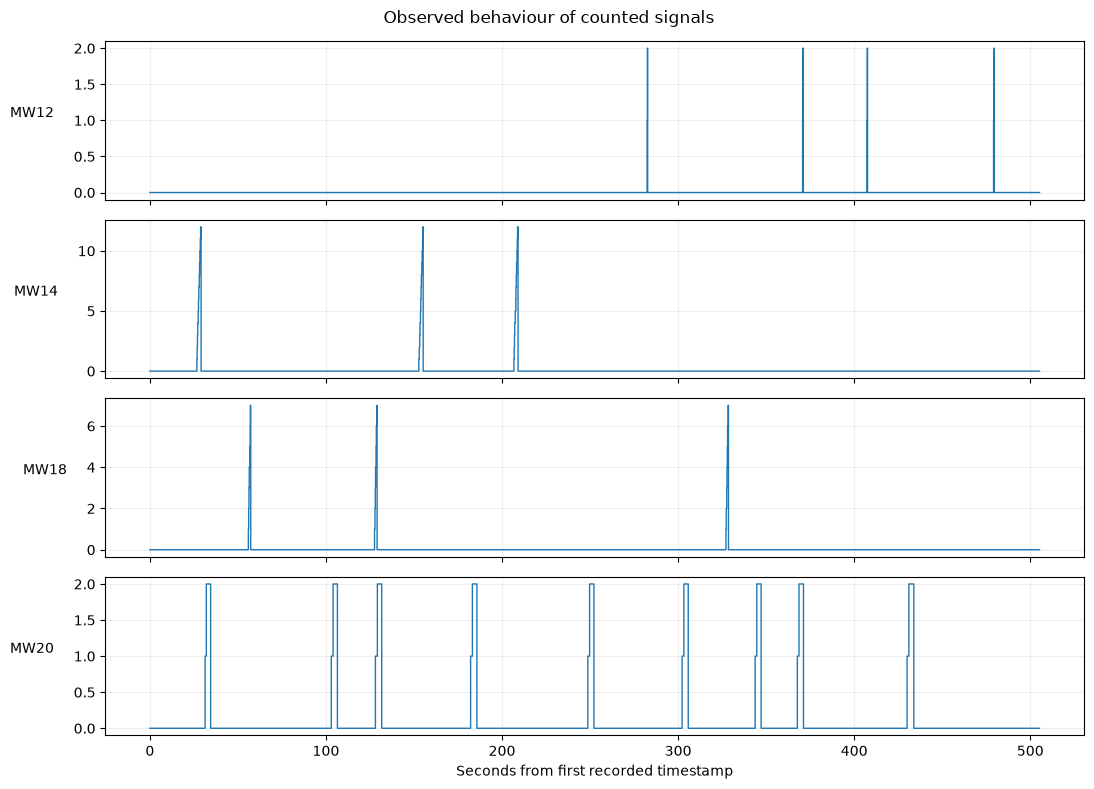


Read-only: X and source data unchanged.


In [6]:
import matplotlib.pyplot as plt  # plotting library
import pandas as pd  # tables

if 'X' not in globals() or 'data' not in globals():  # need cell 4
    raise NameError('Run cell 4 first: this cell needs X and data.')

COUNTED_SIGNALS = ['MW12', 'MW14', 'MW18', 'MW20']  # the counted signals
missing = [c for c in COUNTED_SIGNALS if c not in X.columns]  # in X?
if missing:  # stop if one is missing
    raise ValueError(f'Missing from X: {missing}')

if len(data) != len(X) or not data.index.equals(X.index):  # same rows?
    raise ValueError('data and X are misaligned; rebuild X in cell 4.')

utc = pd.to_datetime(data['utc_time'], utc=True, format='ISO8601')  # times
elapsed_s = (utc - utc.iloc[0]).dt.total_seconds()  # seconds since start

rows = []  # one row per counted signal
for column in COUNTED_SIGNALS:  # every counted signal
    values = X[column]  # its values
    delta = values.diff()  # change from the previous row
    changes = delta[delta.notna() & delta.ne(0)]  # rows where it changed
    rows.append({
        'signal': column,
        'changes': len(changes),  # number of changes
        'increases': int((changes > 0).sum()),  # changes upward
        'increases_by_1': int(changes.eq(1).sum()),  # upward by exactly 1
        'decreases': int((changes < 0).sum()),  # changes downward
        'decreases_to_zero': int(((delta < 0) & values.eq(0)).sum()),  # 0
        'never_decreases': bool((delta.dropna() >= 0).all()),  # cumulative?
    })

count_profile = pd.DataFrame(rows).set_index('signal')  # summary table
print(count_profile.to_string())  # show the table

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)  # 4 panels
for axis, column in zip(axes, COUNTED_SIGNALS):  # one panel per signal
    axis.step(elapsed_s, X[column], where='post', linewidth=1)  # steps
    axis.set_ylabel(column, rotation=0, labelpad=30)  # signal name
    axis.grid(alpha=0.2)  # light grid

axes[-1].set_xlabel('Seconds from first recorded timestamp')  # x title
fig.suptitle('Observed behaviour of counted signals')  # figure title
fig.tight_layout()  # avoid overlapping text
plt.show()  # draw the figure

print('\nRead-only: X and source data unchanged.')

**What:**
- Profile the four counted signals MW12, MW14, MW18 and MW20: how often they change, how many increases and decreases, whether they increase by 1, where they decrease to, and whether they ever decrease
- Plot each of them over time as a step line

**Why:**
- We want to know if these counts accumulate over the whole recording (which would act like a time trend) or restart (which makes them process states)
- The cell stops with an error if a signal is missing in X or data and X do not have the same rows
- Read-only: X and the source data stay unchanged

**Output:**
- MW12: 12 changes, 8 increases (all by 1), 4 decreases (all to zero)
- MW14: 39 changes, 36 increases (all by 1), 3 decreases (all to zero)
- MW18: 24 changes, 21 increases (all by 1), 3 decreases (all to zero)
- MW20: 27 changes, 18 increases (all by 1), 9 decreases (all to zero)
- never_decreases is False for all four
- Figure with 4 panels sharing the time axis (seconds from the first timestamp)

**Next:** decide if the four counted signals stay in the model

The table and the plot support keeping MW12, MW14, MW18 and MW20 for now.

- Evidence: every observed increase is +1 and every decrease ends at zero. The plot shows short counting episodes separated by zero, not counts that keep accumulating over the recording.
- So our earlier concern about a cumulative time trend is not supported here.
- Together with the dictionary description "counted steps", they are reasonable candidates for numerical count features. We decide the scaling separately, because their ranges differ.
- Limits: this does not tell us what triggers the return to zero, or whether one episode is one completed part. A short episode is not automatically an anomaly.

**Decision:** we keep MW12, MW14, MW18 and MW20. No change to X is needed, they are already included.


MW22: rows per recorded code
MW22
0     127
1    5030
2     614
3     174

Observed transition counts:
from_code  to_code
0.0        1          9
1.0        2          8
           3          1
2.0        0          7
           3          1
3.0        0          2
First 24 successive codes: [1, 2, 3, 0, 1, 2, 0, 1, 2, 0, 1, 3, 0, 1, 2, 0, 1, 2, 0, 1, 2, 0, 1, 2]

AW256: rows per recorded code
AW256
10        173
4353     5264
13059     264
40970     143
43530     101

Observed transition counts:
from_code  to_code
10.0       4353       1
           40970      7
4353.0     10         3
           13059      9
13059.0    4353       9
40970.0    4353       2
           43530      5
43530.0    10         4
           4353       1
First 24 successive codes: [10, 40970, 43530, 10, 40970, 4353, 13059, 4353, 13059, 4353, 13059, 4353, 13059, 4353, 13059, 4353, 10, 40970, 43530, 10, 40970, 4353, 13059, 4353]


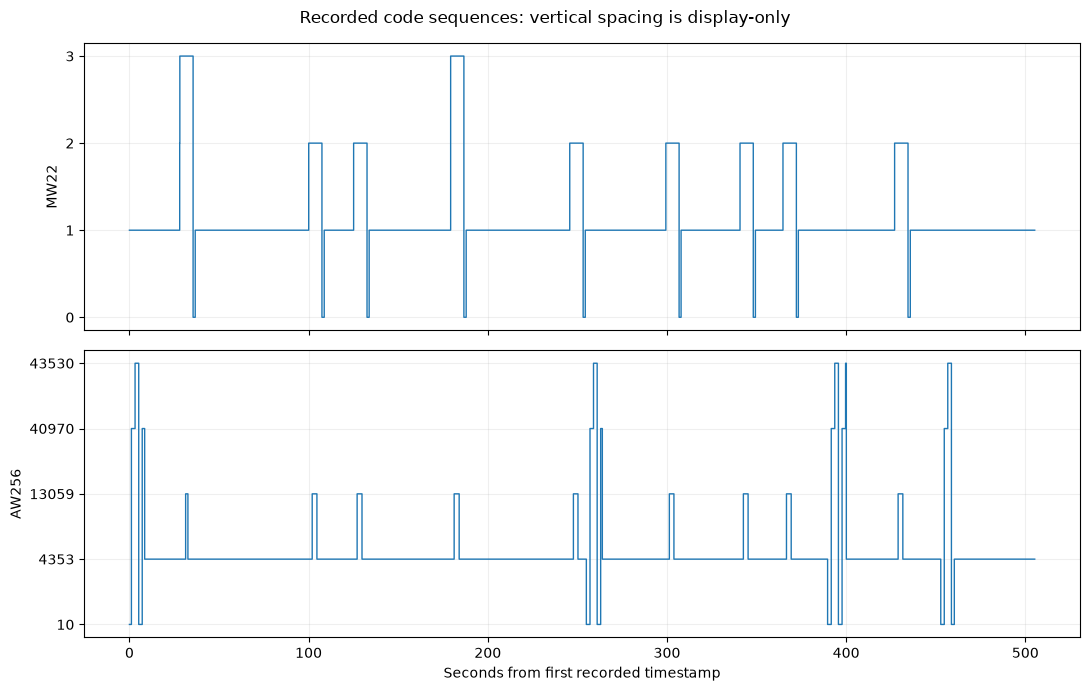


Read-only: no encoding applied; X unchanged.


In [7]:
import pandas as pd  # tables
import matplotlib.pyplot as plt  # plotting library

if 'X' not in globals() or 'data' not in globals():  # need cell 4
    raise NameError('Run cell 4 first: this cell needs X and data.')
if not X.index.equals(data.index):  # same rows?
    raise ValueError('X and data are misaligned; rebuild X in cell 4.')

utc = pd.to_datetime(data['utc_time'], utc=True, format='ISO8601')  # times
elapsed_s = (utc - utc.iloc[0]).dt.total_seconds()  # seconds since start
code_signals = ['MW22', 'AW256']  # the two code signals

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)  # 2 panels

for axis, column in zip(axes, code_signals):  # one panel per signal
    values = X[column]  # its values
    print(f'\n{column}: rows per recorded code')
    print(values.value_counts().sort_index().to_string())  # rows per code

    changed = values.ne(values.shift())  # rows where the code changes
    sequence = values.loc[changed].reset_index(drop=True)  # successive codes
    transitions = pd.DataFrame({  # from-to pairs
        'from_code': sequence.shift(),  # previous code
        'to_code': sequence,  # new code
    }).iloc[1:]  # the first row has no previous code
    print('\nObserved transition counts:')
    print(
        transitions.groupby(['from_code', 'to_code'])  # each pair
        .size().rename('count').to_string()  # how often it occurs
    )
    print('First 24 successive codes:', sequence.iloc[:24].tolist())

    codes = sorted(values.unique())  # distinct codes in order
    display_positions = {code: i for i, code in enumerate(codes)}  # y slots
    axis.step(  # step line of the display positions
        elapsed_s, values.map(display_positions),
        where='post', linewidth=1,
    )
    axis.set_yticks(range(len(codes)))  # one tick per code
    axis.set_yticklabels([str(code) for code in codes])  # label = the code
    axis.set_ylabel(column)  # signal name
    axis.grid(alpha=0.2)  # light grid

axes[-1].set_xlabel('Seconds from first recorded timestamp')  # x title
fig.suptitle('Recorded code sequences: vertical spacing is display-only')
fig.tight_layout()  # avoid overlapping text
plt.show()  # draw the figure

print('\nRead-only: no encoding applied; X unchanged.')

**What:**
- Look at the recorded code sequences of MW22 and AW256: rows per code, how often the code changes from one value to the next, and the first 24 successive codes
- Plot both as step lines (the vertical spacing only shows the order of the codes, it is not a measurement)

**Why:**
- Both look like state codes (MW22: which cycle is going on, AW256: data word that controls the light). We check whether their numerical gaps could mean anything before we decide how to encode them
- The cell stops with an error if X or data are missing or misaligned (they come from cell 4)
- Read-only: no encoding yet, X unchanged

**Output:**
- MW22 rows per code: 0 = 127, 1 = 5030, 2 = 614, 3 = 174. Common transitions: 0 to 1 (9), 1 to 2 (8), 2 to 0 (7). Rare: 1 to 3 (1), 2 to 3 (1), 3 to 0 (2)
- AW256 rows per code: 10 = 173, 4353 = 5264, 13059 = 264, 40970 = 143, 43530 = 101. Common transitions: 4353 to 13059 (9), 13059 to 4353 (9), 10 to 40970 (7), 40970 to 43530 (5)
- The first 24 codes of MW22 run 1, 2, 3, 0, 1, 2, 0, 1, 2, 0, ... so the codes repeat and return to earlier values

**Next:** decide how these two code signals enter the model

### Decision: one-hot encode MW22 and AW256

We keep both signals, but change how the model sees them: one 0/1 column for each recorded code.

- MW22: the dictionary says it tells which cycle is going on. The codes repeat and return to earlier values (cell 11). We have no evidence that the numerical difference between two cycle codes is a meaningful distance.
- AW256: the dictionary describes it as the data word that controls the light. Its five values are recorded control states, and their numerical gaps are not established as measurements. Treating 43530 as larger than 4353 would be an unsupported assumption.
- One-hot encoding does not assume an order or a size. For example, MW22 code 2 becomes 1 in its own column and 0 in the other MW22 columns. It does not tell us which code is normal or faulty.
- Effect on the matrix: 2 columns are replaced by 9 indicator columns, 152 - 2 + 4 + 5 = 159 columns. All 5,945 rows stay.
- Open point: a larger number of encoded columns must not silently give a signal more weight in the model distance. We handle each signal's contribution separately.
- The other five unresolved signals stay unchanged for now (cell 14).

In [8]:
import pandas as pd  # tables

if 'X' not in globals():  # need cell 4
    raise NameError('Run cell 4 first: this cell needs X.')
if X.shape[1] != 152:  # X must still be the 152-feature matrix
    raise ValueError(f'Expected 152 columns in X, found {X.shape[1]}.')

CODE_SIGNALS = ['MW22', 'AW256']  # signals to encode
EXPECTED_CODES = {  # codes seen in the audit
    'MW22': {0, 1, 2, 3},
    'AW256': {10, 4353, 13059, 40970, 43530},
}

for column in CODE_SIGNALS:  # check each signal
    observed = set(X[column].dropna().unique())  # codes in the data
    if X[column].isna().any() or observed != EXPECTED_CODES[column]:
        raise ValueError(f'{column}: codes differ from the audit: {observed}')
    print(f'{column}: {sorted(observed)}')  # list the codes

indicators = pd.get_dummies(  # one 0/1 column per code
    X[CODE_SIGNALS].astype(str),
    prefix=CODE_SIGNALS,
    dtype=int,
)
X_encoded = pd.concat(  # originals out, indicators in
    [X.drop(columns=CODE_SIGNALS), indicators], axis=1
)

assert X_encoded.index.equals(X.index)  # same rows
assert X_encoded.shape == (len(X), 159)  # 152 - 2 + 9
for column in CODE_SIGNALS:  # check each indicator block
    block_columns = [  # the columns of this signal
        c for c in indicators.columns if c.startswith(column + '_')
    ]
    assert indicators[block_columns].sum(axis=1).eq(1).all()  # one per row

print('Original X:', X.shape, '(unchanged)')
print('X_encoded:', X_encoded.shape)  # (5945, 159)
print('New indicator columns:', indicators.columns.tolist())
print('No rows removed. No scaling or model training.')

MW22: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
AW256: [np.int64(10), np.int64(4353), np.int64(13059), np.int64(40970), np.int64(43530)]
Original X: (5945, 152) (unchanged)
X_encoded: (5945, 159)
New indicator columns: ['MW22_0', 'MW22_1', 'MW22_2', 'MW22_3', 'AW256_10', 'AW256_13059', 'AW256_40970', 'AW256_4353', 'AW256_43530']
No rows removed. No scaling or model training.


**What:**
- One-hot encode MW22 and AW256: build 0/1 indicator columns, one for each code, and replace the two original columns with them
- Check that the codes are exactly the ones from the audit, that there are no missing values and that each indicator block sums to 1 in every row
- The result is X_encoded; X stays unchanged

**Why:**
- These two signals are state codes, so we do not let the model treat the gaps between codes as distances (cell 12)
- The checks stop the cell if the data changed since the audit

**Output:**
- MW22 codes: 0, 1, 2, 3. AW256 codes: 10, 4353, 13059, 40970, 43530
- Original X: (5945, 152), unchanged
- X_encoded: (5945, 159)
- New columns: MW22_0, MW22_1, MW22_2, MW22_3, AW256_10, AW256_13059, AW256_40970, AW256_4353, AW256_43530
- No rows removed, no scaling, no model training

**Next:** look at the five remaining unresolved signals

In [9]:
FIVE = [  # the five unresolved signals
    'MW26', 'MD28', 'MW32',
    'WH.desiredPalletX', 'WH.desiredPalletY',
]

if 'X' not in globals() or 'data' not in globals():  # need cell 4
    raise NameError('Run cell 4 first: this needs X and data.')
if not X.index.equals(data.index):  # same rows?
    raise ValueError('X and data are misaligned; rebuild X in cell 4.')

for name in FIVE:  # one summary per signal
    values = X[name]  # its values
    changed = values.ne(values.shift())  # rows where the value changes
    sequence = values.loc[changed].tolist()  # successive values
    print(f'\n{name}: {values.nunique()} distinct values')
    print('Changes after first row:', int(changed.sum()) - 1)  # not row 1
    print('Rows per value:', values.value_counts().sort_index().to_dict())
    print('First 20 successive values:', sequence[:20])

print('\nTIMING-RELATED COLUMNS:')
timing_columns = [  # columns that may relate to timing
    'MW26', 'MD28', 'MW32', 'EW256', 'EW258'
]
missing = [c for c in timing_columns if c not in data.columns]  # present?
if missing:  # stop if one is missing
    raise ValueError(f'Missing expected columns: {missing}')
print(
    data.groupby(timing_columns, dropna=False)  # each combination
    .size().rename('rows').to_string()  # rows per combination
)

print('\nRECORDED PALLET TARGET PAIRS:')
print(
    X.groupby(['WH.desiredPalletX', 'WH.desiredPalletY'])  # each pair
    .size().rename('rows').to_string()  # rows per pair
)

print('\nRow counts are not durations. No decoding or changes applied.')


MW26: 7 distinct values
Changes after first row: 14
Rows per value: {16384: 57, 32768: 4726, 34816: 538, 36864: 209, 40960: 232, 43008: 88, 45056: 95}
First 20 successive values: [43008, 40960, 32768, 40960, 32768, 36864, 45056, 40960, 32768, 34816, 43008, 40960, 32768, 16384, 32768]

MD28: 2 distinct values
Changes after first row: 2
Rows per value: {33554435: 5887, 33554451: 58}
First 20 successive values: [33554435, 33554451, 33554435]

MW32: 2 distinct values
Changes after first row: 2
Rows per value: {34819: 58, 59395: 5887}
First 20 successive values: [59395, 34819, 59395]

WH.desiredPalletX: 4 distinct values
Changes after first row: 8
Rows per value: {910: 1937, 1620: 1332, 1640: 635, 2330: 2041}
First 20 successive values: [1620, 910, 2330, 1640, 910, 2330, 1620, 910, 2330]

WH.desiredPalletY: 3 distinct values
Changes after first row: 3
Rows per value: {110: 1774, 540: 2055, 1030: 2116}
First 20 successive values: [110, 540, 1030, 110]

TIMING-RELATED COLUMNS:
MW26   MD28   

**What:**
- Look at the five remaining unresolved signals MW26, MD28, MW32, WH.desiredPalletX and WH.desiredPalletY: distinct values, changes, rows per value and the first successive values
- Group the rows by the timing-related columns MW26, MD28, MW32, EW256 and EW258 to see which values occur together
- Count the recorded pallet X/Y target pairs

**Why:**
- We cannot turn these values into seconds or positions from the dictionary alone, so we first look at what is actually recorded
- The cell stops with an error if X, data or a timing column is missing
- Read-only: no decoding, X unchanged

**Output:**
- MW26: 7 values, 14 changes. Rows per value: 16384 = 57, 32768 = 4726, 34816 = 538, 36864 = 209, 40960 = 232, 43008 = 88, 45056 = 95
- MD28: 33554435 (5887 rows) and 33554451 (58 rows), 2 changes. MW32: 59395 (5887 rows) and 34819 (58 rows), 2 changes
- In the timing table (8 groups) the 58-row MD28 / MW32 excursion occurs together and only with MW26 = 36864 (58 of its 209 rows). EW256 and EW258 are 1 in every group
- WH.desiredPalletX: 910 = 1937, 1620 = 1332, 1640 = 635, 2330 = 2041 rows. WH.desiredPalletY: 110 = 1774, 540 = 2055, 1030 = 2116 rows
- 9 recorded X/Y pairs, 530 to 802 rows each
- Row counts are not durations

**Next:** decide how the five signals enter the model

### Decision: one-hot encode the five remaining signals

The results show recurring recorded values. They do not establish physical units or a timing conversion. We keep all five signals and provisionally encode each recorded value as a category.

- MW26: 7 values, 14 changes. We keep which value occurs and do not assume the numerical gaps are elapsed time.
- MD28 and MW32: each has a baseline value and a 58-row excursion. We keep both. Matching row counts do not prove that both changed on the same rows by themselves (cell 14 shows they do coincide with MW26 = 36864), and a rare value is not proof of a fault.
- WH.desiredPalletX / WH.desiredPalletY: we keep the 4 X targets and 3 Y targets as categories. If they are physical coordinates, this loses the distance between targets. We document that as a limitation.
- Reason: we keep the observed distinctions without inventing a conversion or a physical distance. One-hot encoding still assumes that different codes are equally different. It is a starting representation, not a verified decoding.
- Effect: X_encoded grows from 159 to 172 columns. All rows stay, and the original values stay in X.

In [10]:
import pandas as pd  # tables

if 'X_encoded' not in globals():  # need cell 13
    raise NameError('Run cell 13 first: this cell needs X_encoded.')

CODE_SIGNALS = {  # signals to encode and the values seen in the audit
    'MW26': {16384, 32768, 34816, 36864, 40960, 43008, 45056},
    'MD28': {33554435, 33554451},
    'MW32': {34819, 59395},
    'WH.desiredPalletX': {910, 1620, 1640, 2330},
    'WH.desiredPalletY': {110, 540, 1030},
}

for column, expected in CODE_SIGNALS.items():  # check each signal
    if column not in X_encoded.columns:  # column must exist
        raise ValueError(f'Missing column: {column}')
    observed = set(X_encoded[column].dropna().unique())  # values in data
    if X_encoded[column].isna().any() or observed != expected:
        raise ValueError(f'{column}: values differ from audit: {observed}')

indicators = pd.get_dummies(  # one 0/1 column per value
    X_encoded[list(CODE_SIGNALS)].astype(str),
    prefix=list(CODE_SIGNALS),
    dtype=int,
)
X_prepared = pd.concat(  # originals out, indicators in
    [X_encoded.drop(columns=CODE_SIGNALS), indicators], axis=1
)

assert X_prepared.index.equals(X_encoded.index)  # same rows
assert X_prepared.shape == (len(X_encoded), 172)  # 159 - 5 + 18
for column in CODE_SIGNALS:  # check each indicator block
    block = [c for c in indicators.columns if c.startswith(column + '_')]
    assert indicators[block].sum(axis=1).eq(1).all()  # one per row

print('X_encoded:', X_encoded.shape, '(unchanged)')
print('X_prepared:', X_prepared.shape)  # (5945, 172)
print('Five columns replaced by 18 indicators; all rows retained.')
print('No scaling or model training yet.')

X_encoded: (5945, 159) (unchanged)
X_prepared: (5945, 172)
Five columns replaced by 18 indicators; all rows retained.
No scaling or model training yet.


**What:**
- One-hot encode the five remaining signals MW26, MD28, MW32, WH.desiredPalletX and WH.desiredPalletY on top of X_encoded
- Replace the five columns with indicator columns (one per recorded value) and check that each block sums to 1 in every row
- The result is X_prepared; X and X_encoded stay unchanged

**Why:**
- We cannot convert these values to time or position, so we do not let the model use their numerical gaps (cell 15)
- The checks stop the cell if the data differ from the audit

**Output:**
- 5 columns become 18 indicator columns (7 + 2 + 2 + 4 + 3)
- X_prepared: (5945, 172), computed as 159 - 5 + 18
- No rows removed, no scaling, no model training

**Next:** summarize all exclusions and run the consistency check

### What was left out of X and what was only replaced

- 43 signal columns are not in X:
  - 40 have one observed value throughout this recording
  - A200.4, A200.5 and A200.6 match the retained pusher outputs A0.2, A0.3 and A0.4 exactly
- The 7 timing and merge helper columns are also kept outside the model features.
- The later .drop() calls are replacements, not information removals: MW22 and AW256 became 9 indicator columns, and the next five signals became 18 indicator columns. Their original values remain in X.
- No source columns or rows were deleted.

In [11]:
import pandas as pd  # tables

issues = []  # collects every problem found
helpers = {  # timing and merge columns kept outside the model
    'utc_time', 'timestamp_beckhoff', 'beck_time', 'beck_age_ms',
    'timestamp_siemens', 'sie_time', 'sie_age_ms',
}

if not all(name in globals() for name in ['data', 'X', 'exclusions']):
    raise NameError('Run cell 4 first: data, X and exclusions are needed.')

expected_outside = helpers | set(exclusions['column'])  # should be outside X
actual_outside = set(data.columns) - set(X.columns)  # really outside X
if actual_outside != expected_outside:  # lists must be identical
    issues.append(
        'Outside X differs from the documented list: '
        f'{sorted(actual_outside ^ expected_outside)}'
    )
if not set(X.columns).issubset(data.columns):  # X must come from data
    issues.append('X contains columns not in source data.')
elif not X.equals(data[X.columns]):  # values and rows must match
    issues.append('Retained values or row alignment differ from source.')

print('Outside X:', len(actual_outside), 'columns')  # 50
print('Documented signal exclusions:', len(exclusions))  # 43
print('Timing/merge helpers:', len(helpers))  # 7


def check_encoding(previous, current, codes, label):  # recompute and compare
    expected_indicators = pd.get_dummies(  # indicators from the input table
        previous[codes].astype(str), prefix=codes, dtype=int,
    )
    expected = pd.concat(  # originals out, indicators in
        [previous.drop(columns=codes), expected_indicators], axis=1
    )
    if not current.equals(expected):  # stored result must be identical
        issues.append(f'{label}: values, columns or rows differ.')
    print(f'{label}: {previous.shape} -> {current.shape}')


if 'X_encoded' in globals():  # first encoding built?
    check_encoding(X, X_encoded, ['MW22', 'AW256'], 'First encoding')
else:
    issues.append('X_encoded is not built; cell 13 is pending.')

if 'X_prepared' in globals() and 'X_encoded' in globals():  # second one?
    check_encoding(
        X_encoded, X_prepared,
        ['MW26', 'MD28', 'MW32', 'WH.desiredPalletX', 'WH.desiredPalletY'],
        'Second encoding',
    )
else:
    issues.append('X_prepared is not built; cell 16 is pending.')

if issues:  # something is wrong
    print('\nCHECK RESULTS:')
    for issue in issues:  # list each issue
        print('-', issue)
else:  # all checks passed
    print('\nPASS: exclusions match the documented list.')
    print('Retained values and rows match the source.')
    print('Both encodings preserve the recorded codes exactly.')

print('\nRead-only check; no tables or source files changed.')

Outside X: 50 columns
Documented signal exclusions: 43
Timing/merge helpers: 7
First encoding: (5945, 152) -> (5945, 159)
Second encoding: (5945, 159) -> (5945, 172)

PASS: exclusions match the documented list.
Retained values and rows match the source.
Both encodings preserve the recorded codes exactly.

Read-only check; no tables or source files changed.


**What:**
- Run a consistency check over the whole feature preparation: the columns outside X must equal the 43 documented exclusions plus the 7 timing and merge helper columns
- Check that X equals the source columns it keeps, and recompute both encodings from their inputs to see if the stored X_encoded and X_prepared match exactly
- Print PASS or the list of issues

**Why:**
- It shows that no column was dropped or changed without a documented reason, and that both encodings only re-express the recorded values
- Read-only: no table or file is changed

**Output:**
- Outside X: 50 columns (43 documented signal exclusions + 7 helpers)
- First encoding: (5945, 152) to (5945, 159). Second encoding: (5945, 159) to (5945, 172)
- PASS: the exclusions match the documented list, the retained values and rows match the source, and both encodings keep the recorded codes exactly

**Next:** print the review list of the excluded signals.

In [12]:
if not all(name in globals() for name in ['data', 'exclusions', 'book']):
    raise NameError(  # need cell 4 and cell 2
        'This needs data/exclusions from cell 4 and book from cell 2.'
    )

COMM_PAIRS = {  # excluded copy: retained pusher output
    'A200.4': 'A0.2',
    'A200.5': 'A0.3',
    'A200.6': 'A0.4',
}


def dictionary_meaning(name):  # dictionary text for a signal
    entries = book.get(name, [])  # dictionary entries
    if not entries:  # signal is not in the dictionary
        return 'NOT FOUND IN DICTIONARY'
    return ' | '.join(  # one part per sheet
        f'[{sheet}] ' + '; '.join(  # sheet name and its non-empty fields
            str(value) for value in row[1:]
            if value is not None and str(value).strip()
        )
        for sheet, row in entries
    )


excluded_names = list(exclusions['column'])  # all 43 excluded signals
constant_names = [c for c in excluded_names if c not in COMM_PAIRS]  # 40

print('CONSTANT-SIGNAL REVIEW')
print('Observed value does not establish normal/active/error status.')
for number, name in enumerate(constant_names, 1):  # one entry per signal
    values = data[name]  # its values
    observed = values.dropna().unique().tolist()  # distinct values
    verified = len(observed) == 1 and values.notna().all()  # constant?
    print(f'\n{number}. {name}: observed={observed}; constant={verified}')
    print('Meaning:', dictionary_meaning(name))  # dictionary text

print('\nCOMMUNICATION-COLUMN REVIEW')
for name, kept in COMM_PAIRS.items():  # each excluded copy
    matches = data[name].equals(data[kept])  # identical to the original?
    print(f'\nExcluded: {name}; retained: {kept}; identical={matches}')
    print('Excluded meaning:', dictionary_meaning(name))
    print('Retained meaning:', dictionary_meaning(kept))

print('\nENCODING ASSUMPTIONS, NOT EXCLUSIONS')
print('MW22, AW256, MW26, MD28, MW32 and pallet X/Y remain represented.')
print('One-hot preserves code identity, not original numerical distances.')
print('Code meanings, physical units and equal-difference assumptions')
print('are not established merely by successfully creating indicators.')
print('\nRead-only: no changes and no model training.')

CONSTANT-SIGNAL REVIEW
Observed value does not establish normal/active/error status.

1. VG.I3_ref_switch_rotate: observed=[False]; constant=True
Meaning: [Beckhoff] Robot

2. WH.I4_Ref_swtich_vertical: observed=[False]; constant=True
Meaning: [Beckhoff] Warehouse

3. WH.A1_trail_sensor_lower: observed=[False]; constant=True
Meaning: [Beckhoff] Warehouse

4. WH.A2_trail_sensor_upper: observed=[False]; constant=True
Meaning: [Beckhoff] Warehouse

5. VG.safeCurtainLong: observed=[True]; constant=True
Meaning: [Beckhoff] Robot

6. Pallets.Conveyor_belt_lift: observed=[800]; constant=True
Meaning: [Beckhoff] Conveyor belt

7. VG.atHome: observed=[False]; constant=True
Meaning: [Beckhoff] Robot

8. VG.error_robot: observed=[False]; constant=True
Meaning: [Beckhoff] Robot

9. M34.4: observed=[False]; constant=True
Meaning: [Siemens] Bool; Not used; -; -

10. M38.0: observed=[False]; constant=True
Meaning: [Siemens] Bool; Siemens hard reset on/off; Main; Mbit_SR_hard_reset

11. M38.1: observe

**What:**
- Print the review list of the 43 excluded signals: for each of the 40 constant signals the observed value, whether it is constant, and its dictionary meaning
- For the 3 communication columns A200.4, A200.5 and A200.6: whether they are identical to the retained A0.2, A0.3 and A0.4, with both dictionary meanings
- Print a short note on the encoded signals (not exclusions)

**Why:**
- It lets us read each exclusion next to its dictionary entry. An observed value does not tell us if that value is normal, active or an error
- The cell stops with an error if data, exclusions or book are missing
- Read-only: no changes, no model training

**Output:**
- Numbered list of the 40 constant signals, each with constant=True, for example VG.safeCurtainLong observed [True] ("Robot") and Pallets.Conveyor_belt_lift observed [800] ("Conveyor belt")
- Many Siemens entries are bits of the sorting station, for example M2.0 to M2.3 and M3.0, M3.1 (pusher timer and SR bits), and C0, C1, C2 (sorting counters for white, red, blue blocks, always 0)
- The three communication columns with identical=True
- The note that MW22, AW256, MW26, MD28, MW32 and pallet X/Y stay represented, as indicators that keep code identity but not numerical distance

**Next:** save the same review as a text file (cell 20).

In [13]:
from pathlib import Path  # file paths

if not all(name in globals() for name in ['data', 'exclusions', 'book']):
    raise NameError(  # need cell 4 and cell 2
        'Needs data/exclusions from cell 4 and book from cell 2.'
    )

COMM_PAIRS = {'A200.4': 'A0.2', 'A200.5': 'A0.3', 'A200.6': 'A0.4'}  # copy


def review_meaning(name):  # dictionary text for a signal
    entries = book.get(name, [])  # dictionary entries
    if not entries:  # signal is not in the dictionary
        return 'NOT FOUND IN DICTIONARY'
    return ' | '.join(  # one part per sheet
        f'[{sheet}] ' + '; '.join(  # sheet name and its non-empty fields
            str(value) for value in row[1:]
            if value is not None and str(value).strip()
        )
        for sheet, row in entries
    )


lines = [  # header of the text file
    'B4 feature exclusion review',
    f'Source shape: {data.shape}',
    f'Excluded signals: {len(exclusions)}',
    '',
    'CONSTANT SIGNALS',
    'Recorded values do not establish normal/active/error status.',
]
constant_names = [c for c in exclusions['column'] if c not in COMM_PAIRS]  # 40
for number, name in enumerate(constant_names, 1):  # one entry per signal
    values = data[name]  # its values
    lines.append(  # observed values, missing and distinct counts
        f'\n{number}. {name}: '
        f'observed={values.dropna().unique().tolist()}, '
        f'missing={int(values.isna().sum())}, '
        f'distinct={values.nunique(dropna=True)}'
    )
    lines.append('Meaning: ' + review_meaning(name))  # dictionary text

lines.append('\nCOMMUNICATION COLUMNS')
for name, kept in COMM_PAIRS.items():  # each excluded copy
    lines.append(  # identical to the retained original?
        f'\n{name} vs retained {kept}: '
        f'identical={data[name].equals(data[kept])}'
    )
    lines.append('Excluded meaning: ' + review_meaning(name))
    lines.append('Retained meaning: ' + review_meaning(kept))

lines.extend([  # closing note on the encoded signals
    '\nENCODED, NOT EXCLUDED',
    'MW22, AW256, MW26, MD28, MW32, WH.desiredPalletX/Y.',
    'Indicators preserve code identity, not original numerical distances.',
    'Physical units and equal-difference assumptions remain unverified.',
])

output_path = OUT_DIR / 'feature_exclusion_review.txt'
output_path.write_text('\n'.join(lines), encoding='utf-8')  # write the file
print('Saved:', output_path)  # show where it went
print('Source data and feature tables unchanged.')


Saved: /Users/lakshminarayanareddymandu/Downloads/B4 Project/02_Data_and_Outputs/Generated_Outputs/feature_exclusion_review.txt
Source data and feature tables unchanged.


**What:**
- Build the same review text as cell 19 (40 constant signals, 3 communication columns, note on the encoded signals) and save it as feature_exclusion_review.txt in the output directory folder
- For each constant signal the file lists the observed values, the number of missing values and of distinct values, and the dictionary meaning

**Why:**
- A saved file we can attach to the report. It documents why each of the 43 signals is not in X
- The cell stops with an error if data, exclusions or book are missing
- It writes only this text file. The source data and the feature tables are unchanged

**Output:**
- Saved: feature_exclusion_review.txt

**Next:** continue with the model input (scaling is still open).